## 1. Loading the data and giving every listing a color.
The artist's dots got their colors from "what every traveller weighs before booking": price, reviews per month and availability. 
We turn each into a percentile rank (0 = lowest, 1 = highest), so all three are on the same scale, and convert the map position to kilometres.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA

df = pd.read_csv("data/paris_listings.csv")
print(df.shape)

ranks = df[["price", "reviews_per_month", "availability_365"]].rank(pct=True).values
x_km = ((df.longitude - 2.34) * 111 * np.cos(np.radians(48.86))).values
y_km = ((df.latitude - 48.86) * 111).values

J = np.c_[ranks, x_km / 10, y_km / 10]
print("search space:", J.shape)

(28108, 18)
search space: (28108, 5)


## 2. Finding the artist's dots.
Real listings fill the space like a cloud. The dots are drawn letters, with each letter being a flat 2D sheet. So for every listing we look at it's 20 nearest neigbours and measure how close they are, and how "flat" they are (share of their spread in the top 2 directions)
For fake dots: close neighbours and a flat neighbourhood. they form a separate group in the plot below.

artist's dots found: 1651 of 28108


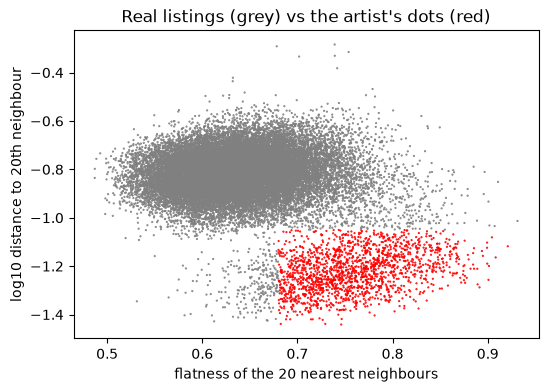

In [ ]:
K = 20
dist, idx = NearestNeighbors(n_neighbors=K + 1).fit(J).kneighbors(J)

neigh = J[idx[:, 1:]]                                         
neigh = neigh - neigh.mean(axis=1, keepdims=True)
spread = np.linalg.eigvalsh(np.einsum("nki,nkj->nij", neigh, neigh) / K)[:, ::-1]   
flat_share = (spread[:, 0] + spread[:, 1]) / spread.sum(axis=1)                     
near = dist[:, -1]                                                                   

fake = (near < 10 ** -1.05) & (flat_share > 0.68)
print("artist's dots found:", fake.sum(), "of", len(df))

plt.figure(figsize=(6, 4))
plt.scatter(flat_share, np.log10(near), s=0.3, c=np.where(fake, "red", "grey"))
plt.xlabel("flatness of the 20 nearest neighbours")
plt.ylabel("log10 distance to 20th neighbour")
plt.title("Real listings (grey) vs the artist's dots (red)")
plt.savefig("figures/separation.png", dpi=120)
plt.show()

## 3. Spliting the dots into letters.
HDBSCAN groups the artist's dots into dense clusters. One letter can come out in two pieces, so clusters that touch (as in they're less than 0.15 apart) are merged. Resulting, in this case, 6 letters.

In [3]:
lab = np.full(len(df), -1)                                   
lab[fake] = HDBSCAN(min_cluster_size=40, min_samples=8).fit_predict(J[fake])

groups = [c for c in np.unique(lab) if c != -1]
for a in groups:
    for b in groups:
        if a < b and (lab == a).any() and (lab == b).any():
            gap = NearestNeighbors(n_neighbors=1).fit(J[lab == a]).kneighbors(J[lab == b])[0].min()
            if gap < 0.15:                                 
                lab[lab == b] = a

letters = [c for c in np.unique(lab) if c != -1]
print(len(letters), "letters:", {int(c): int((lab == c).sum()) for c in letters})

6 letters: {0: 263, 1: 281, 2: 259, 3: 261, 4: 336, 5: 249}


e:\Hackathon\.venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


## 4. The order: Paris arrondissements
Each letter sits mostly in one district (arrondissement). Paris districts are numbered 1-20 in a spiral from the centre, so we read the leters in order of their median district number.

In [4]:
ARR = {"Louvre": 1, "Bourse": 2, "Temple": 3, "Hôtel-de-Ville": 4, "Panthéon": 5, "Luxembourg": 6,
       "Palais-Bourbon": 7, "Élysée": 8, "Opéra": 9, "Entrepôt": 10, "Popincourt": 11, "Reuilly": 12,
       "Gobelins": 13, "Observatoire": 14, "Vaugirard": 15, "Passy": 16, "Batignolles-Monceau": 17,
       "Buttes-Montmartre": 18, "Buttes-Chaumont": 19, "Ménilmontant": 20}

def key(name):
    return re.sub(r"[^a-z]", "", str(name).lower())

ARR_KEY = {key(k): v for k, v in ARR.items()}
arr = df.neighbourhood.map(lambda s: ARR_KEY.get(key(s), np.nan))
assert arr.notna().all(), "a neighbourhood was not recognised"

order = sorted(letters, key=lambda c: np.nanmedian(arr[lab == c]))
for c in order:
    top = arr[lab == c].value_counts(normalize=True).head(3).round(2).to_dict()
    print(f"cluster {c}: median arrondissement {np.nanmedian(arr[lab == c]):.0f}   (shares: {top})")

cluster 0: median arrondissement 4   (shares: {4: 0.42, 5: 0.16, 3: 0.15})
cluster 1: median arrondissement 9   (shares: {9: 0.67, 2: 0.26, 1: 0.04})
cluster 4: median arrondissement 10   (shares: {11: 0.33, 2: 0.23, 10: 0.21})
cluster 3: median arrondissement 11   (shares: {11: 0.61, 4: 0.18, 12: 0.13})
cluster 2: median arrondissement 15   (shares: {15: 0.89, 7: 0.11})
cluster 5: median arrondissement 17   (shares: {17: 0.7, 9: 0.15, 18: 0.1})


## 5. Reading each letter
Since every letter is a flat drawing tilted in the 5D space, we flatte it onto its plane (by using PCA) and then compare it with rendered capital letters from A-Z in every rotation (5 degree steps) and mirror the image.
In this case, the score will be the average distance between the dots and the letter shape. The lower it is, the better the match.

In [5]:
import string
from PIL import Image, ImageDraw, ImageFont
from matplotlib import font_manager
from scipy.spatial import cKDTree

FONT = ImageFont.truetype(font_manager.findfont("DejaVu Sans:bold"), 150)


def whiten(P):
    P = P - P.mean(0)
    w, V = np.linalg.eigh(np.cov(P.T))
    return P @ V @ np.diag(1 / np.sqrt(w)) @ V.T


def template(ch):
    img = Image.new("L", (200, 200), 0)
    ImageDraw.Draw(img).text((100, 100), ch, fill=255, font=FONT, anchor="mm")
    ys, xs = np.nonzero(np.array(img) > 128)
    return whiten(np.c_[xs, -ys].astype(float))


def best_fit(P, T):
    best = (np.inf, None)
    for mirror in (1, -1):
        for ang in np.radians(np.arange(0, 360, 5)):
            R = np.array([[np.cos(ang), -np.sin(ang)], [np.sin(ang), np.cos(ang)]]) @ np.diag([mirror, 1])
            X = P @ R.T
            score = cKDTree(T).query(X)[0].mean() + cKDTree(X).query(T)[0].mean()
            if score < best[0]:
                best = (score, X)
    return best


TEMPLATES = {ch: template(ch) for ch in string.ascii_uppercase}
flat = {c: whiten(PCA(2).fit_transform(J[lab == c])) for c in order}
for pos, c in enumerate(order, 1):
    scores = sorted((best_fit(flat[c], T)[0], ch) for ch, T in TEMPLATES.items())
    print(f"letter {pos} (cluster {c}): " + "  ".join(f"{ch} {s:.2f}" for s, ch in scores[:4]))

letter 1 (cluster 0): L 0.19  A 0.20  V 0.20  P 0.21
letter 2 (cluster 1): Z 0.14  N 0.15  S 0.16  M 0.17
letter 3 (cluster 4): O 0.12  Q 0.12  D 0.13  G 0.16
letter 4 (cluster 3): U 0.12  Q 0.17  O 0.18  R 0.18
letter 5 (cluster 2): R 0.18  U 0.23  J 0.23  B 0.24
letter 6 (cluster 5): E 0.17  G 0.20  W 0.23  B 0.23


## 6. The resulting word, labels.csv and the figure.
Reading the best-matching letter at each position, in arrondissement order, gives the word "LZOURE" (Due to Z and N being the same shape, and L and A being a tie within the noise). However, that word does not exist, so we have to make the final call manually by looking at the alternative letters (A and N). "ANOURE", is a real word and would make sense in the context of the puzzle.

{'O': 336, 'N': 281, 'A': 263, 'U': 261, 'R': 259, 'E': 249}


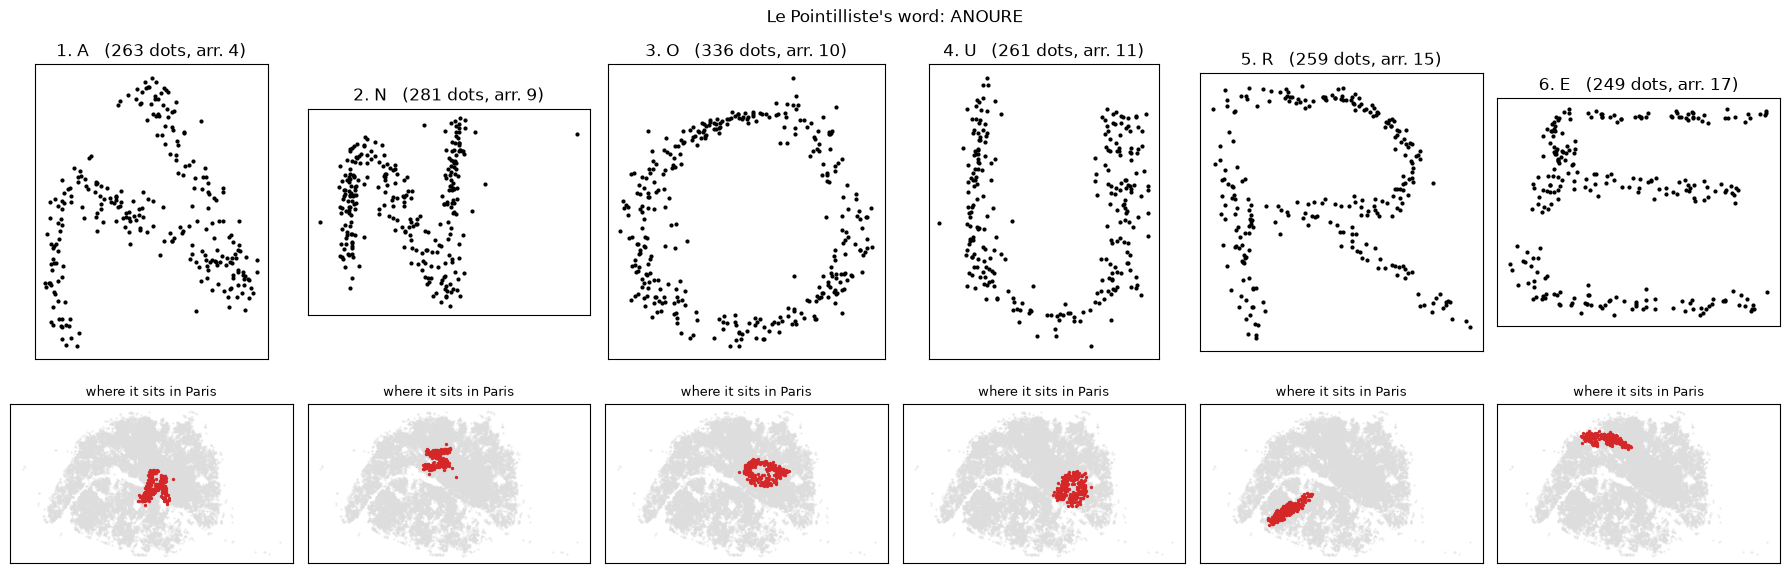

FLAG: SIGMOID_ANOURE


In [6]:
WORD = "ANOURE"                      
assert len(WORD) == len(order)

letter_of = {c: ch for c, ch in zip(order, WORD)}
labels = pd.DataFrame({
    "listing_id": df.listing_id,
    "letter": [letter_of.get(c, "") for c in lab],
    "position": [order.index(c) + 1 if c in order else 0 for c in lab],
})
labels.to_csv("labels.csv", index=False)
print(labels[labels.letter != ""].letter.value_counts().to_dict())

fig, ax = plt.subplots(2, len(order), figsize=(3 * len(order), 6.5))
for j, c in enumerate(order):
    ch = WORD[j]
    _, X = best_fit(flat[c], TEMPLATES[ch])                 
    ax[0, j].scatter(X[:, 0], X[:, 1], s=4, c="k"); ax[0, j].set_aspect("equal")
    ax[0, j].set_title(f"{j + 1}. {ch}   ({int((lab == c).sum())} dots, arr. {np.nanmedian(arr[lab == c]):.0f})")
    ax[1, j].scatter(x_km, y_km, s=0.1, c="#dddddd")
    ax[1, j].scatter(x_km[lab == c], y_km[lab == c], s=2, c="tab:red")
    ax[1, j].set_aspect("equal"); ax[1, j].set_title("where it sits in Paris", fontsize=9)
for a in ax.flat:
    a.set_xticks([]); a.set_yticks([])
fig.suptitle(f"Le Pointilliste's word: {WORD}")
plt.tight_layout()
plt.savefig("figures/letters.png", dpi=110)
plt.show()

print("FLAG: SIGMOID_" + WORD)